# Task 5 - Feature Engineering & Tuned Ensembles for Regression
**Dataset:** Ames House Prices (`data/train.csv`) | **Target:** `SalePrice` (modelled as `log1p(SalePrice)`) | **Problem:** regression

**Question this notebook answers:** how much of a model's improvement comes from *better features and proper validation*, and how much from a *fancier algorithm*?

**Plan**
1. Load data, make one hold-out split that stays untouched until the very end
2. Engineer 7 domain features (each justified in writing)
3. 5-fold cross-validation (mean ± std of RMSE) on the training split
4. Random Forest and XGBoost, each tuned with `RandomizedSearchCV` on the same 5 folds
5. One comparison table, significance check, final verdict, one-time hold-out evaluation

**Leakage rule:** feature engineering, imputation and encoding live *inside* a scikit-learn `Pipeline`, so they are re-fitted on the training part of every fold. All code is in `task5_lib.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import task5_lib as lib

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

N_ITER = 30   # random-search iterations per model (use 10 for a faster run)

## 1. Load data and make the hold-out split

In [2]:
df = lib.load_data()
print(df.shape)
X_train, X_test, y_train, y_test = lib.split_data(df)
print(f"train={len(X_train)}  hold-out={len(X_test)}  (hold-out is NOT used until step 8)")
df["SalePrice"].describe().round(0)

(1460, 81)
train=1168  hold-out=292  (hold-out is NOT used until step 8)


count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

Prices are right-skewed, so the target is `log1p(SalePrice)`. Errors then become *relative*: an RMSE of 0.13 means a typical miss of about 13% of the price. **All RMSE values in this notebook are on this log scale.**

## 2. Engineered features (each justified)

In [3]:
for name, text in lib.FEATURE_JUSTIFICATIONS.items():
    print(f"* {name}: {text}\n")

* TotalSF: TotalBsmtSF + 1stFlrSF + 2ndFlrSF. Buyers think in total usable area, not in separate floors. One strong, additive size signal is easier for a tree to split on than three partial ones.

* HouseAge: YrSold - YearBuilt (clipped at 0). The raw year does not say how old the house was when it sold; age at sale does, and older houses usually sell for less, all else equal.

* TotalBath: FullBath + 0.5*HalfBath + BsmtFullBath + 0.5*BsmtHalfBath. Bathrooms are split over four columns; a half bath is worth roughly half a full one. The total is what a buyer counts.

* HasRemodeled: 1 if YearRemodAdd != YearBuilt else 0. A remodel flag captures 'updated house' separately from raw age.

* RemodAge: YrSold - YearRemodAdd (clipped at 0). Years since the last update; a recent remodel makes an old house feel newer.

* TotalPorchSF: OpenPorchSF + EnclosedPorch + 3SsnPorch + ScreenPorch + WoodDeckSF. Five sparse outdoor-area columns summed into one usable 'outdoor living space' number.

* HasP

In [4]:
# Sanity check on the TRAIN split only (reporting only, not used to select features)
lib.feature_check_table(X_train, y_train)

,feature,corr_with_log_price,min,max
0,TotalSF,0.762,334.0,11752.0
1,HouseAge,-0.577,0.0,136.0
2,TotalBath,0.659,1.0,6.0
3,HasRemodeled,-0.074,0.0,1.0
4,RemodAge,-0.564,0.0,60.0
5,TotalPorchSF,0.396,0.0,1027.0
6,HasPool_or_Fireplace,0.507,0.0,1.0


**Leakage check:** every feature is computed from columns known *before* the sale (areas, years, counts). None uses `SalePrice` or price bins. `HasRemodeled` has a weak correlation on its own; it is kept because a tree can use it in combination with age, and the CV result below decides whether the whole set helps.

## 3. Baseline (Task 3 style): default Random Forest, original features, 5-fold CV

In [5]:
base = lib.cv_untuned(
    "Baseline RF (default, original features)",
    lib.make_pipeline(lib.rf_estimator().set_params(n_estimators=300), add_features=False),
    X_train, y_train,
    "Task 3 style baseline: no new features, no tuning.",
)
print(f"RMSE per fold: {np.round(base['rmse_folds'], 4)}")
print(f"mean ± std   : {base['cv_rmse_mean']:.4f} ± {base['cv_rmse_std']:.4f}")

RMSE per fold: [0.1482 0.1514 0.1741 0.135  0.128 ]
mean ± std   : 0.1473 ± 0.0177


> If your Task 3 baseline used a different model or number, put its mean CV RMSE next to this one in your write-up. This baseline is rebuilt here so it is measured on exactly the same 5 folds.

## 4. Same default Random Forest + engineered features (isolates the effect of the features)

In [6]:
rf_fe = lib.cv_untuned(
    "RF (default) + engineered features",
    lib.make_pipeline(lib.rf_estimator().set_params(n_estimators=300), add_features=True),
    X_train, y_train,
    "Same algorithm and settings; only the features changed.",
)
print(f"RMSE per fold: {np.round(rf_fe['rmse_folds'], 4)}")
print(f"mean ± std   : {rf_fe['cv_rmse_mean']:.4f} ± {rf_fe['cv_rmse_std']:.4f}")

RMSE per fold: [0.1479 0.1516 0.1639 0.1305 0.1225]
mean ± std   : 0.1433 ± 0.0167


## 5. Random Forest tuned with `RandomizedSearchCV` (5 hyperparameters, same 5 folds)

In [7]:
rf_tuned = lib.cv_tuned(
    "Random Forest (tuned) + features",
    lib.make_pipeline(lib.rf_estimator(), add_features=True),
    lib.rf_param_distributions(), X_train, y_train, N_ITER,
    "Bagging: many deep trees averaged, robust, low variance.",
)
print(rf_tuned["best_params"])
print(f"mean ± std: {rf_tuned['cv_rmse_mean']:.4f} ± {rf_tuned['cv_rmse_std']:.4f}")

{'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 300}
mean ± std: 0.1381 ± 0.0183


## 6. XGBoost tuned with `RandomizedSearchCV` (7 hyperparameters, same 5 folds)

In [8]:
boost_name, boost_est, boost_dist, is_xgb = lib.boosting_model()
print("Using:", boost_name)
xgb_tuned = lib.cv_tuned(
    boost_name,
    lib.make_pipeline(boost_est, add_features=True),
    boost_dist, X_train, y_train, N_ITER,
    "Boosting: shallow trees added one by one to fix earlier errors; more tuning-sensitive.",
)
print(xgb_tuned["best_params"])
print(f"mean ± std: {xgb_tuned['cv_rmse_mean']:.4f} ± {xgb_tuned['cv_rmse_std']:.4f}")

Using: GradientBoosting (tuned) [XGBoost NOT installed - stand-in]


C:\Users\HP 840 G5\AppData\Local\Temp\ipykernel_46432\3539125377.py:1: UserWarning: xgboost is not installed / not working -> using sklearn GradientBoostingRegressor as a stand-in. Run `pip install xgboost` and re-run to get the real XGBoost result.
  boost_name, boost_est, boost_dist, is_xgb = lib.boosting_model()


{'learning_rate': 0.10196967939171485, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 645, 'subsample': 0.9706635463175177}
mean ± std: 0.1220 ± 0.0155


*If the line above says `NOT installed - stand-in`, run `pip install xgboost`, restart the kernel and run all cells again, so the table contains real XGBoost numbers.*

## 7. Comparison table

In [9]:
results = [base, rf_fe, rf_tuned, xgb_tuned]
table = lib.comparison_table(results)
table

,Model,Mean CV RMSE (log),Mean CV R²,Training time (s),Final fit time (s),Note
0,"Baseline RF (default, original features)",0.1473 ± 0.0177,0.8571 ± 0.0225,29.7,20.82,"Task 3 style baseline: no new features, no tuning."
1,RF (default) + engineered features,0.1433 ± 0.0167,0.8650 ± 0.0187,25.2,19.65,Same algorithm and settings; only the features changed.
2,Random Forest (tuned) + features,0.1381 ± 0.0183,0.8746 ± 0.0215,239.9,6.23,"Bagging: many deep trees averaged, robust, low variance."
3,GradientBoosting (tuned) [XGBoost NOT installed - stand-in],0.1220 ± 0.0155,0.9020 ± 0.0168,225.2,11.38,Boosting: shallow trees added one by one to fix earlier errors; more tuning-...


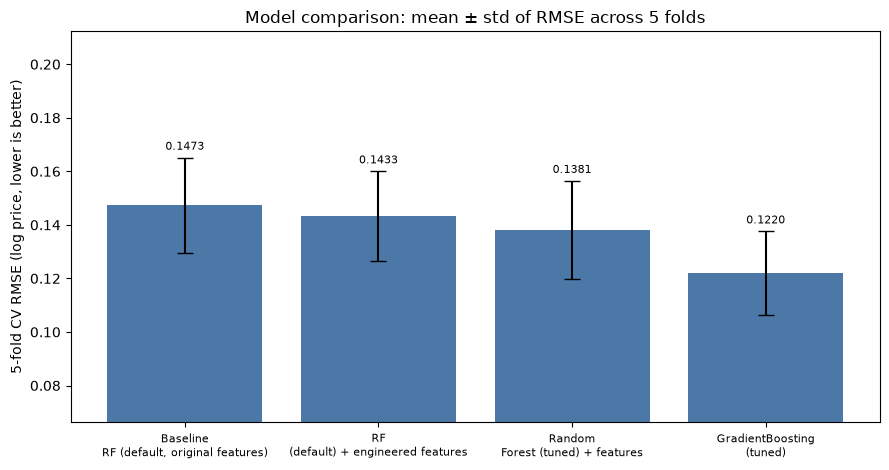

In [10]:
lib.plot_cv_comparison(results);

*Training time* = wall-clock for the whole 5-fold CV (untuned rows) or the whole random search (tuned rows). *Final fit time* = one fit on the full training split.

### Is the improvement bigger than noise?

In [11]:
rows = []
for r in (rf_fe, rf_tuned, xgb_tuned):
    d = lib.paired_improvement(base, r)
    rows.append({
        "model vs baseline": r["model"].split(" [")[0],
        "RMSE drop": round(d["mean_rmse_drop"], 4),
        "relative %": round(d["relative_improvement_pct"], 1),
        "folds improved": f"{d['folds_improved']}/{d['n_folds']}",
        "paired t p-value": round(d["p_value"], 4),
        "meaningful?": d["meaningful"],
    })
pd.DataFrame(rows)

,model vs baseline,RMSE drop,relative %,folds improved,paired t p-value,meaningful?
0,RF (default) + engineered features,0.0040,2.7,4/5,0.0996,False
1,Random Forest (tuned) + features,0.0093,6.3,5/5,0.0120,True
2,GradientBoosting (tuned),0.0253,17.2,5/5,0.0003,True


**Rule used for "meaningful":** all folds improve, the mean drop is more than 2 standard errors of the paired fold differences, and the relative gain is at least 3%. The p-values are only a guide, because the folds share training data. Also remember that the tuned scores are slightly optimistic: the search picked the winner on these same folds. That is why the hold-out set exists.

## 8. Choose the model, then touch the hold-out set exactly once

In [12]:
chosen, why = lib.choose_model_to_ship([rf_tuned, xgb_tuned])
print("Chosen:", chosen["model"])
print(why)

chosen_fit = lib.fit_on_train(chosen["fitted"], X_train, y_train)
hold = lib.evaluate_holdout(chosen_fit, X_test, y_test)

# Baseline on hold-out is for reference only, it plays no role in the choice
base_fit = lib.fit_on_train(base["pipeline"], X_train, y_train)
hold_base = lib.evaluate_holdout(base_fit, X_test, y_test)

pd.DataFrame({
    "Model": [chosen["model"].split(" [")[0], "Task 3 style baseline (reference)"],
    "Hold-out RMSE (log)": [round(hold["rmse_log"], 4), round(hold_base["rmse_log"], 4)],
    "Hold-out R2": [round(hold["r2"], 4), round(hold_base["r2"], 4)],
    "Hold-out RMSE ($)": [f"{hold['rmse_usd']:,.0f}", f"{hold_base['rmse_usd']:,.0f}"],
})

Chosen: GradientBoosting (tuned) [XGBoost NOT installed - stand-in]
GradientBoosting (tuned) [XGBoost NOT installed - stand-in] has the lowest mean CV RMSE (0.1220) and no faster model is within one standard error of it.


,Model,Hold-out RMSE (log),Hold-out R2,Hold-out RMSE ($)
0,GradientBoosting (tuned),0.1358,0.9011,"27,624"
1,Task 3 style baseline (reference),0.1463,0.8854,"29,610"


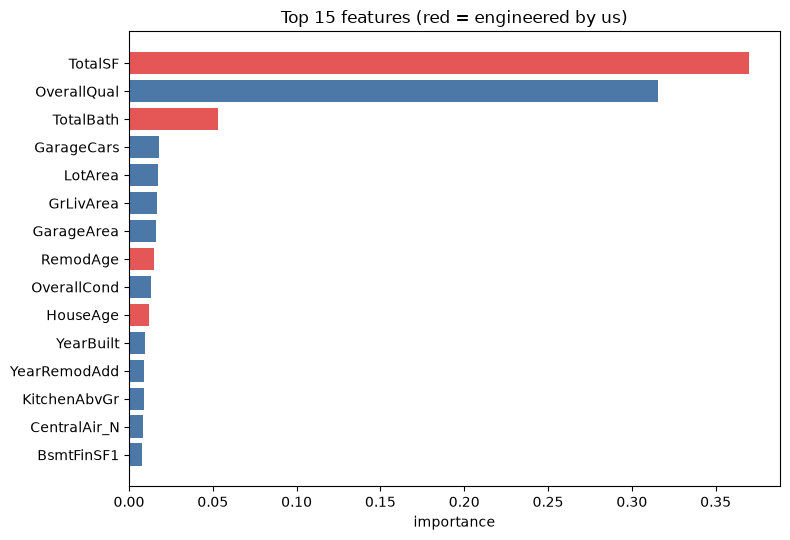

In [13]:
lib.plot_feature_importance(chosen_fit);

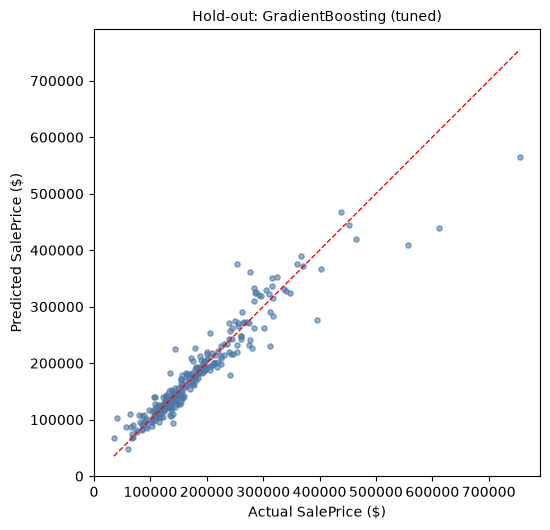

In [14]:
lib.plot_holdout(y_test, hold["pred_log"], "Hold-out: " + chosen["model"].split(" [")[0]);

## 9. Verdict

In [15]:
imp = lib.paired_improvement(base, chosen)
imp_fe = lib.paired_improvement(base, rf_fe)
hold_gain = (hold_base["rmse_log"] - hold["rmse_log"]) / hold_base["rmse_log"] * 100

print(f"Model I would ship : {chosen['model'].split(' [')[0]}")
print(f"CV RMSE            : {chosen['cv_rmse_mean']:.4f} ± {chosen['cv_rmse_std']:.4f}  "
      f"(baseline {base['cv_rmse_mean']:.4f} ± {base['cv_rmse_std']:.4f})")
print(f"Improvement (CV)   : {imp['mean_rmse_drop']:.4f} RMSE = {imp['relative_improvement_pct']:.1f}% , "
      f"{imp['folds_improved']}/{imp['n_folds']} folds better")
print(f"   of which features alone: {imp_fe['mean_rmse_drop']:.4f} RMSE = {imp_fe['relative_improvement_pct']:.1f}%")
print(f"Improvement (hold-out, one look): {hold_gain:.1f}% lower log-RMSE than baseline")
print(f"Cost               : full tuning {chosen['total_time_s']:.0f}s vs baseline CV {base['total_time_s']:.0f}s; "
      f"final fit {chosen['final_fit_time_s']:.1f}s")
print()
if imp["meaningful"]:
    print("Meaningful: all folds improved, the gain beats 2 standard errors and is >= 3%. "
          "The extra complexity and training time are justified.")
elif imp["mean_rmse_drop"] > 0:
    print("Modest: the gain is real in direction but does not clear every condition of the rule, "
          "so the extra complexity is only partly justified.")
else:
    print("No improvement over the baseline: the added complexity is not justified.")

Model I would ship : GradientBoosting (tuned)
CV RMSE            : 0.1220 ± 0.0155  (baseline 0.1473 ± 0.0177)
Improvement (CV)   : 0.0253 RMSE = 17.2% , 5/5 folds better
   of which features alone: 0.0040 RMSE = 2.7%
Improvement (hold-out, one look): 7.1% lower log-RMSE than baseline
Cost               : full tuning 225s vs baseline CV 30s; final fit 11.4s

Meaningful: all folds improved, the gain beats 2 standard errors and is >= 3%. The extra complexity and training time are justified.


**Write your verdict in your own words below** (2-4 sentences). Say which model you would ship, quote the CV and hold-out numbers from above, and say honestly whether the gain is big enough compared with the baseline to justify the extra complexity and training time. Mention the caveats: one 80/20 split, tuned CV scores are slightly optimistic, and small differences can be noise.